**Resolución de problemas de regresión lineal, transformando el problema en un formato de optimización binaria combinatoria, QUBO (Quadratic Unconstrained Binary Optimization), para luego resolverlo utilizando Redes de Tensores (MPO-DMRG).**

# Optimización Combinatoria Binaria (QUBO) mediante Operadores de Producto de Matriz (MPO-DMRG)

Este cuaderno aborda la resolución de problemas de **Regresión Lineal** desde una perspectiva disruptiva: transformando un problema de optimización continua clásico en un problema de **Optimización Binaria Cuántica No Restringida (QUBO - Quadratic Unconstrained Binary Optimization)**.

En lugar de resolver las ecuaciones normales de mínimos cuadrados mediante álgebra lineal tradicional, discretizamos el espacio de los pesos (coeficientes de la regresión) utilizando una codificación binaria de espines. Esto transforma la búsqueda de los parámetros óptimos en la búsqueda del **estado fundamental (Ground State) de un Hamiltoniano de Ising de muchos cuerpos**.

Para hallar esta solución de manera eficiente sin sufrir la maldición de la dimensionalidad (ya que el espacio de búsqueda crece como $2^N$), implementamos un solucionador cuántico-inspirado basado en **Redes de Tensores**: representamos el coste del problema como un **Matrix Product Operator (MPO)** y aplicamos el algoritmo de **Density Matrix Renormalization Group (DMRG)**. Este enfoque simula de forma clásica las tácticas de entrelazamiento y minimización de energía propias de un recocido cuántico (*Quantum Annealing*).

### **SOLUCIÓN ARTÍCULO PROBLEMAS DE REGRESIÓN**


In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

### Encoding 2

In [ ]:
def build_encoding_vector(alpha, beta):
    """
    Construye el vector extendido del encoding #2.
    Ejemplo:
    alpha=2, beta=0 potencias:[2^0, 2^-1, 2^-2]
    Nw = suma = 1 + 0.5 + 0.25 = 1.75
    vector:[-1.75, 1, 0.5, 0.25]
    """
    powers = [2**t for t in range(beta, -alpha - 1, -1)]
    Nw = sum(powers)

    return np.array([-Nw] + powers)

Construcción T y QUBO

In [ ]:
def build_T(m, encoding_vector):
    return np.kron(np.eye(m), encoding_vector)
def build_qubo(Phi, y, T):
    Lambda = Phi @ Phi.T
    p = Phi @ y

    Q = T.T @ Lambda @ T
    w = 2 * (T.T @ p)

    Q_tilde = Q - np.diag(w)

    return Q_tilde

Solver QUBO brute force:  Minimiza: u^T Q u probando todas las configuraciones binarias.

In [ ]:
def solve_qubo_bruteforce(Q):
    n = Q.shape[0]

    best_energy = np.inf
    best_u = None

    for bits in itertools.product([0, 1], repeat=n):
        u = np.array(bits)

        energy = u.T @ Q @ u

        if energy < best_energy:
            best_energy = energy
            best_u = u

    return best_u, best_energy

Decodificación

In [ ]:
def decode_solution(T, u):
    return T @ u

### **Problema 1**

Solución analítica:
[ 0.75 -1.75]
Encoding vector:
[-1.75  1.    0.5   0.25]
u* =
[0 0 1 1 1 0 0 0]
Energy = -24.875
Solución QUBO:
[ 0.75 -1.75]


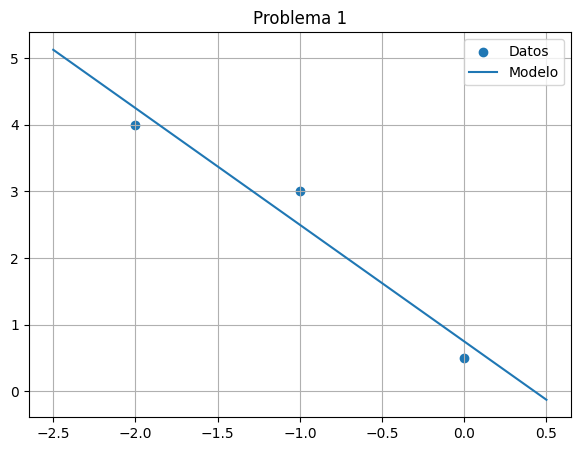

In [ ]:
X1 = np.array([0, -1, -2])
y1 = np.array([0.5, 3, 4])
Phi1 = np.array([
    [1, 1, 1],
    [0, -1, -2]
])
q_analytic_1 = np.linalg.inv(Phi1 @ Phi1.T) @ Phi1 @ y1

print("Solución analítica:")
print(q_analytic_1)
#QUBO
alpha = 2
beta = 0

encoding_vector = build_encoding_vector(alpha, beta)

print("Encoding vector:")
print(encoding_vector)
m1 = 2 #parametros
T1 = build_T(m1, encoding_vector)
Q1 = build_qubo(Phi1, y1, T1)
u1, energy1 = solve_qubo_bruteforce(Q1)

print("u* =")
print(u1)

print("Energy =", energy1)
q_qubo_1 = decode_solution(T1, u1)

print("Solución QUBO:")
print(q_qubo_1)
x_plot = np.linspace(-2.5, 0.5, 200)

y_plot = q_qubo_1[0] + q_qubo_1[1] * x_plot

plt.figure(figsize=(7,5))
plt.scatter(X1, y1, label="Datos")
plt.plot(x_plot, y_plot, label="Modelo")
plt.legend()
plt.grid(True)
plt.title("Problema 1")
plt.show()

## 2. Representación del coste QUBO como un Operador de Producto de Matriz (MPO)

Una vez obtenida la matriz QUBO, resolver el problema por fuerza bruta implicaría evaluar $2^N$ combinaciones, lo cual es inviable para un número elevado de variables lógicas. Aquí es donde intervienen las **Redes de Tensores**.

Propagamos la matriz QUBO hacia una estructura de operadores locales llamada **Matrix Product Operator (MPO)** (u operador de árbol TTN dependiendo de la topología elegida). El MPO factoriza las interacciones de largo alcance entre los bits en una cadena de tensores interconectados mediante variables virtuales (*bond dimensions*).

El algoritmo **DMRG (Density Matrix Renormalization Group)** realiza un barrido local (*sweep*) optimizando los tensores de un sitio o dos sitios a la vez de forma iterativa. En cada paso, el algoritmo congela el resto de la red y resuelve un problema de valores propios local, disminuyendo sistemáticamente la energía global hasta colapsar en la configuración de bits que minimiza perfectamente la pérdida de la regresión lineal.

In [ ]:
X = np.array([0.0, -1.0, -2.0])
y = np.array([0.5, 3.0, 4.0])

#modelo:f(x)=q0​+q1​x, feature map es:ϕ(x)=(1 x)

Phi = np.vstack([
    np.ones_like(X),
    X
])

#matrices regresión

Lambda = Phi @ Phi.T
p = Phi @ y

#encoding 2: q=Tu

omega = np.array([-1.75, 1.0, 0.5, 0.25])   #(−Nω​,ω1​,ω2​,ω3​)[−1.75,1.75] con resolución: 0.25
m = 2  #q=(q0​,q1​)
L = len(omega)  #bits por parámetro 4

T = np.kron(np.eye(m), omega) #T=Im​⊗ω  #T∈R2×8

#QUBO MATRIX

Q = T.T @ Lambda @ T
w = 2 * T.T @ p

Qsharp = Q - np.diag(w)

n = Qsharp.shape[0]

print(Qsharp)


[[ 35.4375  -5.25    -2.625   -1.3125  -9.1875   5.25     2.625    1.3125]
 [ -5.25   -12.       1.5      0.75     5.25    -3.      -1.5     -0.75  ]
 [ -2.625    1.5     -6.75     0.375    2.625   -1.5     -0.75    -0.375 ]
 [ -1.3125   0.75     0.375   -3.5625   1.3125  -0.75    -0.375   -0.1875]
 [ -9.1875   5.25     2.625    1.3125 -23.1875  -8.75    -4.375   -2.1875]
 [  5.25    -3.      -1.5     -0.75    -8.75    27.       2.5      1.25  ]
 [  2.625   -1.5     -0.75    -0.375   -4.375    2.5     12.25     0.625 ]
 [  1.3125  -0.75    -0.375   -0.1875  -2.1875   1.25     0.625    5.8125]]


Se traduce el problema de optimización combinatoria clásica (QUBO), contenido en la matriz Qsharp, al marco de las Redes de Tensores del tipo MPO (Matrix Product Operator), para luego resolverlo por fuerza bruta y decodificar el resultado en variables reales.

Se realiza mediante el método **Register Sweep**, exuesto en el artículo ***Block-Encoding Tensor Networks and QUBO Embeddings***.

Al ser el sistema pequeño se resuleve realizando todas las combinaciones binarias posibles ($2^{n\_bits}$) mediante np.binary_repr. Para cada una, interroga al MPO para conocer su energía y se queda con el bitstring óptimo (u_optimo_mpo). Para sistemas más grandes se utilizará DMRG.

In [ ]:
import numpy as np

n = Qsharp.shape[0]

# EXTRACCIÓN DE PARÁMETROS DE LA MATRIZ
Q_linear = np.diag(Qsharp)  # Términos lineales h_i, coste individual de activar cada bit $u_i$
J = np.zeros((n, n))        # Interacciones cuadráticas J_ij
for i in range(n):
    for j in range(i+1, n):
        J[i, j] = Qsharp[i, j] + Qsharp[j, i]  # Combinación simétrica, interacciones entre pares de bits ($u_i u_j$)

# Operadores físicos base (dimensión 2x2)
I_flat = np.eye(2)
n_op = np.array([[0, 0], [0, 1]])  # Operador de conteo de bit (0 o 1)

# CONSTRUCCIÓN DEL SWEEP DETERMINISTA DE MPO
mpo_tensors = []

for t in range(n):
    # Identificar qué variables del pasado siguen vivas (tienen conexiones hacia el futuro)
    act_in = [i for i in range(t) if any(J[i, j] != 0 for j in range(t, n))]
    # Identificar qué variables saldrán vivas de este sitio hacia la derecha
    act_out = [i for i in range(t+1) if any(J[i, j] != 0 for j in range(t+1, n))]

    # Dimensión de los enlaces virtuales (Canales + Acumulador + Inyector)
    chi_in = len(act_in) + 2
    chi_out = len(act_out) + 2

    # Tensor local del sitio: (Virtual_In, Virtual_Out, Phys_In, Phys_Out)
    Wt = np.zeros((chi_in, chi_out, 2, 2))

    # Regla 1: El acumulador pasa intacto (Fila 0 -> Columna 0)
    Wt[0, 0] = I_flat

    # Regla 2: El inyector pasa intacto (Última fila -> Última columna)
    Wt[chi_in-1, chi_out-1] = I_flat

    # Regla 3: Inyectar el término lineal del sitio actual al acumulador
    Wt[chi_in-1, 0] = Q_linear[t] * n_op

    # Regla 4: Procesar variables arrastradas del pasado
    for idx_in, var in enumerate(act_in):
        r_idx = idx_in + 1  # Índice de fila en el tensor

        # Si la variable del pasado interactúa con el sitio actual 't', cerramos el QUBO parcial
        if J[var, t] != 0:
            Wt[r_idx, 0] = J[var, t] * n_op

        # Si la variable todavía tiene interacciones más adelante, la ruteamos al siguiente sitio
        if var in act_out:
            c_idx = act_out.index(var) + 1
            Wt[r_idx, c_idx] = I_flat

    # Regla 5: Si el sitio actual 't' abre interacciones hacia el futuro, abrirle un canal nuevo
    if t in act_out:
        c_idx = act_out.index(t) + 1
        Wt[chi_in-1, c_idx] = n_op

    mpo_tensors.append(Wt)
    print(f"Sitio u_{t} -> Tensor MPO construido con forma Virtual: ({chi_in} -> {chi_out})")


def evaluar_coste_mpo(mpo_tensors, u):
    """
    Recorre la cadena de tensores MPO proyectando los índices físicos
    según el bitstring 'u' y devuelve la energía final del acumulador.
    """
    # Estado de frontera izquierdo: comenzamos en el Inyector [0, ..., 1]
    vec = np.zeros(mpo_tensors[0].shape[0])
    vec[-1] = 1.0

    # Contracción secuencial (Sweep de izquierda a derecha)
    for t in range(len(u)):
        bit = u[t]
        # Proyectamos el tensor 4D a 2D usando el bit actual (operador de ocupación)
        Wt_eval = mpo_tensors[t][:, :, bit, bit]
        # Multiplicación de vectores-matrices a través del enlace virtual
        vec = vec @ Wt_eval

    # Extraemos el valor final del Acumulador en la frontera derecha
    return vec[0]


# 2. Algoritmo de optimización sobre el MPO
print("--- OPTIMIZACIÓN BASADA EXCLUSIVAMENTE EN MPO ---")

mejor_energia_mpo = float('inf')
u_optimo_mpo = None
n_bits = len(mpo_tensors)  # En tu caso, 8 bits

# Recorremos el espacio de soluciones buscando el mínimo del MPO
for i in range(2**n_bits):
    # Generamos el bitstring candidato
    u_candidato = np.array([int(b) for b in np.binary_repr(i, width=n_bits)])

    # El MPO evalúa el coste de este bitstring
    energia_mpo = evaluar_coste_mpo(mpo_tensors, u_candidato)

    # Guardamos la combinación si es la que menos energía reporta
    if energia_mpo < mejor_energia_mpo:
        mejor_energia_mpo = energia_mpo
        u_optimo_mpo = u_candidato

print(f"¡Búsqueda completada usando la Red de Tensores!")
print(f"-> u_optimo encontrado:          {u_optimo_mpo}")
print(f"-> Energía mínima del MPO:       {mejor_energia_mpo:.4f}")


# 3. Decodificación de la solución óptima usando tu función
q_final = decode_solution(T, u_optimo_mpo)

print("\n--- PARÁMETROS DE REGRESIÓN DECODIFICADOS ---")
print(f"-> Intercepto (q0): {q_final[0]:.4f}")
print(f"-> Pendiente  (q1): {q_final[1]:.4f}")



Sitio u_0 -> Tensor MPO construido con forma Virtual: (2 -> 3)
Sitio u_1 -> Tensor MPO construido con forma Virtual: (3 -> 4)
Sitio u_2 -> Tensor MPO construido con forma Virtual: (4 -> 5)
Sitio u_3 -> Tensor MPO construido con forma Virtual: (5 -> 6)
Sitio u_4 -> Tensor MPO construido con forma Virtual: (6 -> 7)
Sitio u_5 -> Tensor MPO construido con forma Virtual: (7 -> 8)
Sitio u_6 -> Tensor MPO construido con forma Virtual: (8 -> 9)
Sitio u_7 -> Tensor MPO construido con forma Virtual: (9 -> 2)
--- OPTIMIZACIÓN BASADA EXCLUSIVAMENTE EN MPO ---
¡Búsqueda completada usando la Red de Tensores!
-> u_optimo encontrado:          [0 0 1 1 1 0 0 0]
-> Energía mínima del MPO:       -24.8750

--- PARÁMETROS DE REGRESIÓN DECODIFICADOS ---
-> Intercepto (q0): 0.7500
-> Pendiente  (q1): -1.7500


Se obtiene efectivamente el resultado predicho, pasamos a problemás más complejos.

### **Problema 2** (segunda función del artículo)

In [ ]:
N = 300
x2 = np.arange(N) / N
epsilon = 1e-1
noise = np.random.uniform(-epsilon, epsilon, size=N)
y2 = (
    0.5
    + 0.25 * np.sin(2 * np.pi * x2)
    + 0.125 * np.sin(4 * np.pi * x2)
    + 0.125 * np.sin(6 * np.pi * x2)
    + noise
)
Phi2 = np.array([
    np.ones(N),
    np.sin(2 * np.pi * x2),
    np.sin(4 * np.pi * x2),
    np.sin(6 * np.pi * x2)
])
q_analytic_2 = np.linalg.inv(Phi2 @ Phi2.T) @ Phi2 @ y2

print("Solución analítica:")
print(q_analytic_2)
alpha2 = 3
beta2 = 1

encoding_vector2 = build_encoding_vector(alpha2, beta2)
print(encoding_vector2)
m2 = 4 #numero parametros
T2 = build_T(m2, encoding_vector2)
Q2 = build_qubo(Phi2, y2, T2)

Solución analítica:
[0.50317046 0.23984136 0.11625466 0.13090015]
[-3.875  2.     1.     0.5    0.25   0.125]


In [ ]:
Qsharp=Q2.copy()
print(Qsharp)

[[ 5.67455883e+03 -2.32500000e+03 -1.16250000e+03 -5.81250000e+02
  -2.90625000e+02 -1.45312500e+02 -2.13384865e-13  1.10134124e-13
   5.50670620e-14  2.75335310e-14  1.37667655e-14  6.88338275e-15
  -1.41909271e-13  7.32434946e-14  3.66217473e-14  1.83108737e-14
   9.15543683e-15  4.57771841e-15 -2.13384865e-13  1.10134124e-13
   5.50670620e-14  2.75335310e-14  1.37667655e-14  6.88338275e-15]
 [-2.32500000e+03  5.96195443e+02  6.00000000e+02  3.00000000e+02
   1.50000000e+02  7.50000000e+01  1.10134124e-13 -5.68434189e-14
  -2.84217094e-14 -1.42108547e-14 -7.10542736e-15 -3.55271368e-15
   7.32434946e-14 -3.78030940e-14 -1.89015470e-14 -9.45077350e-15
  -4.72538675e-15 -2.36269337e-15  1.10134124e-13 -5.68434189e-14
  -2.84217094e-14 -1.42108547e-14 -7.10542736e-15 -3.55271368e-15]
 [-1.16250000e+03  6.00000000e+02 -1.90227828e+00  1.50000000e+02
   7.50000000e+01  3.75000000e+01  5.50670620e-14 -2.84217094e-14
  -1.42108547e-14 -7.10542736e-15 -3.55271368e-15 -1.77635684e-15
   3.662

# La optimización pasa a ser Bloque a Bloque, cada parámetro continuo ($q_0, q_1, q_2, q_3$), se codifica en un "bloque" de 6 bits (24 bits) y se optimiza como antes, realizando todas las combinaciones, pero por separado para cada parámetro. El objetivo es probar MPO, no el rendimiento.

In [ ]:
import numpy as np

#para reducir la dimensión de enlace se aplica esta aproximación
Qsharp = np.where(np.abs(Qsharp) < 1e-9, 0.0, Qsharp)

n = Qsharp.shape[0]

# Extracción de parámetros
Q_linear = np.diag(Qsharp)
J = np.zeros((n, n))
for i in range(n):
    for j in range(i+1, n):
        J[i, j] = Qsharp[i, j] + Qsharp[j, i]


# CONSTRUCCIÓN DEL MPO

I_flat = np.eye(2)
n_op = np.array([[0, 0], [0, 1]])
mpo_tensors = []

print("--- CONSTRUYENDO SITIOS MPO (REGISTER SWEEP) ---")
for t in range(n):
    act_in = [i for i in range(t) if any(J[i, j] != 0 for j in range(t, n))]
    act_out = [i for i in range(t+1) if any(J[i, j] != 0 for j in range(t+1, n))]

    chi_in = len(act_in) + 2
    chi_out = len(act_out) + 2

    Wt = np.zeros((chi_in, chi_out, 2, 2))
    Wt[0, 0] = I_flat
    Wt[chi_in-1, chi_out-1] = I_flat
    Wt[chi_in-1, 0] = Q_linear[t] * n_op

    for idx_in, var in enumerate(act_in):
        r_idx = idx_in + 1
        if J[var, t] != 0:
            Wt[r_idx, 0] = J[var, t] * n_op
        if var in act_out:
            c_idx = act_out.index(var) + 1
            Wt[r_idx, c_idx] = I_flat

    if t in act_out:
        c_idx = act_out.index(t) + 1
        Wt[chi_in-1, c_idx] = n_op

    mpo_tensors.append(Wt)

    print(f"Sitio u_{t} -> Forma Virtual: ({chi_in} -> {chi_out})")



def evaluar_coste_mpo(mpo_tensors, u):
    vec = np.zeros(mpo_tensors[0].shape[0])
    vec[-1] = 1.0
    for t in range(len(u)):
        bit = u[t]
        Wt_eval = mpo_tensors[t][:, :, bit, bit]
        vec = vec @ Wt_eval
    return vec[0]



# OPTIMIZACIÓN BLOQUE A BLOQUE

print("\n--- OPTIMIZACIÓN BLOQUE A BLOQUE BASADA EN MPO ---")

u_optimo_mpo = np.zeros(n, dtype=int)
bits_por_parametro = 6
num_parametros = 4

# Optimizamos cada parámetro de forma independiente usando el MPO
for p in range(num_parametros):
    inicio_bloque = p * bits_por_parametro
    fin_bloque = inicio_bloque + bits_por_parametro

    mejor_energia_bloque = float('inf')
    mejores_bits_bloque = None

    # Solo recorremos 2^6 = 64 combinaciones para este bloque
    for i in range(2**bits_por_parametro):
        bits_candidatos = [int(b) for b in np.binary_repr(i, width=bits_por_parametro)]

        # Creamos un string de prueba clonando el óptimo actual y sustituyendo el bloque
        u_prueba = u_optimo_mpo.copy()
        u_prueba[inicio_bloque:fin_bloque] = bits_candidatos

        # Evaluamos el impacto en el MPO
        energia = evaluar_coste_mpo(mpo_tensors, u_prueba)

        if energia < mejor_energia_bloque:
            mejor_energia_bloque = energia
            mejores_bits_bloque = bits_candidatos

    # Fijamos los mejores bits encontrados para este parámetro
    u_optimo_mpo[inicio_bloque:fin_bloque] = mejores_bits_bloque
    print(f"Parámetro q_{p} optimizado -> Bits: {mejores_bits_bloque}")

# Calculamos la energía final del string completo
energia_total_mpo = evaluar_coste_mpo(mpo_tensors, u_optimo_mpo)
print(f"\n-> u_optimo global encontrado: {u_optimo_mpo}")
print(f"-> Energía mínima del MPO:      {energia_total_mpo:.4f}")



#DECODIFICACIÓN

q_final = decode_solution(T2, u_optimo_mpo)

print("\n--- COMPARATIVA DE RESULTADOS ---")
print("Solución Analítica Continua:")
print(f" q0: {q_analytic_2[0]:.4f}, q1: {q_analytic_2[1]:.4f}, q2: {q_analytic_2[2]:.4f}, q3: {q_analytic_2[3]:.4f}")
print("Solución Decodificada desde el MPO:")
print(f" q0: {q_final[0]:.4f}, q1: {q_final[1]:.4f}, q2: {q_final[2]:.4f}, q3: {q_final[3]:.4f}")

--- CONSTRUYENDO SITIOS MPO (REGISTER SWEEP) ---
Sitio u_0 -> Forma Virtual: (2 -> 3)
Sitio u_1 -> Forma Virtual: (3 -> 4)
Sitio u_2 -> Forma Virtual: (4 -> 5)
Sitio u_3 -> Forma Virtual: (5 -> 6)
Sitio u_4 -> Forma Virtual: (6 -> 7)
Sitio u_5 -> Forma Virtual: (7 -> 2)
Sitio u_6 -> Forma Virtual: (2 -> 3)
Sitio u_7 -> Forma Virtual: (3 -> 4)
Sitio u_8 -> Forma Virtual: (4 -> 5)
Sitio u_9 -> Forma Virtual: (5 -> 6)
Sitio u_10 -> Forma Virtual: (6 -> 7)
Sitio u_11 -> Forma Virtual: (7 -> 2)
Sitio u_12 -> Forma Virtual: (2 -> 3)
Sitio u_13 -> Forma Virtual: (3 -> 4)
Sitio u_14 -> Forma Virtual: (4 -> 5)
Sitio u_15 -> Forma Virtual: (5 -> 6)
Sitio u_16 -> Forma Virtual: (6 -> 7)
Sitio u_17 -> Forma Virtual: (7 -> 2)
Sitio u_18 -> Forma Virtual: (2 -> 3)
Sitio u_19 -> Forma Virtual: (3 -> 4)
Sitio u_20 -> Forma Virtual: (4 -> 5)
Sitio u_21 -> Forma Virtual: (5 -> 6)
Sitio u_22 -> Forma Virtual: (6 -> 7)
Sitio u_23 -> Forma Virtual: (7 -> 2)

--- OPTIMIZACIÓN BLOQUE A BLOQUE BASADA EN MPO -

Como funciona correctamente para una función más compleja, se prueba para el entrenamiento de un dataset real

# **DATASET**


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("camnugent/california-housing-prices")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'california-housing-prices' dataset.
Path to dataset files: /kaggle/input/california-housing-prices


# Se compara con el entrenamiento usando el método del artículo: QUBO for regression models

In [ ]:
!pip install dwave-neal

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 77.4 MB/s eta 0:00:00


Generando la matriz QUBO vectorizada con datos de Entrenamiento...
Lanzando Simulated Annealing para 30 qubits...

Pesos óptimos decodificados (w): [ 1.125  0.25   0.    -0.875 -0.75   0.75 ]
RESULTADOS QUBO
TRAIN MAE  : $52,389.12
TRAIN RMSE : $71,627.87
TRAIN R²   : 0.5744
TEST MAE   : $51,542.71
TEST RMSE  : $70,184.39
TEST R²    : 0.5966
Tiempo     : 1.14 s


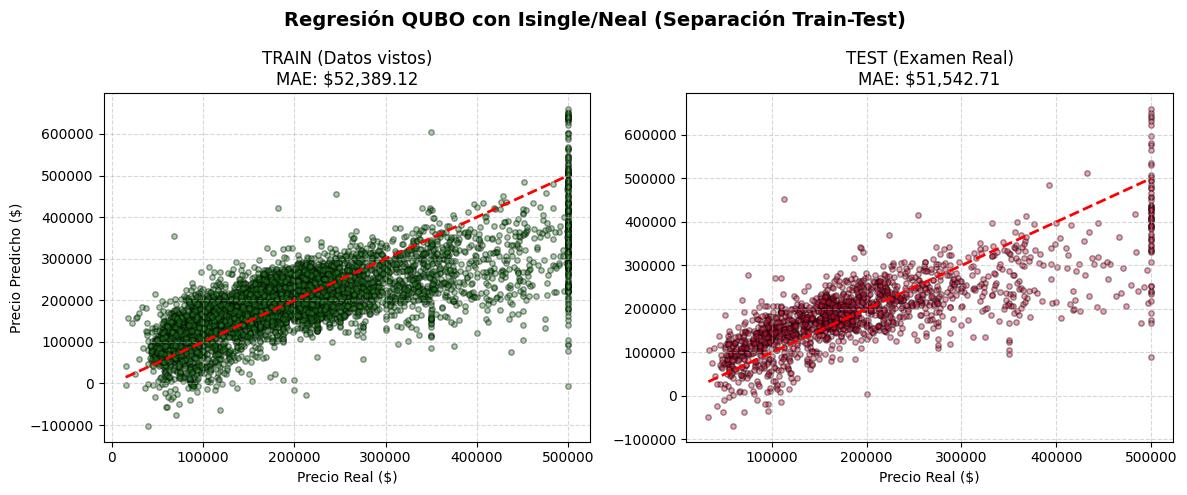

In [ ]:
import os
import pandas as pd
import numpy as np
import neal
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import time
from sklearn.metrics import mean_squared_error, r2_score


csv_path = os.path.join(path, "housing.csv")
df = pd.read_csv(csv_path).dropna()

features_cols = ['median_income', 'total_rooms', 'housing_median_age', 'latitude', 'longitude']
target_col = 'median_house_value'


sample_size = 8000
df_sample = df.iloc[:sample_size]

X_raw = df_sample[features_cols].values
y_raw = df_sample[target_col].values

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.20, random_state=42
)


scaler_X = MinMaxScaler()
X_train_scaled = scaler_X.fit_transform(X_train_raw)
X_test_scaled = scaler_X.transform(X_test_raw)

scaler_y = MinMaxScaler()
y_train_scaled = scaler_y.fit_transform(y_train_raw.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test_raw.reshape(-1, 1)).flatten()

X_train_bias = np.hstack([X_train_scaled, np.ones((X_train_scaled.shape[0], 1))]) #aprender el término independiente
X_test_bias = np.hstack([X_test_scaled, np.ones((X_test_scaled.shape[0], 1))])


Phi = X_train_bias.T
y = y_train_scaled

m = Phi.shape[0]  # 6 parámetros (5 features + 1 bias)
encoding_vec = build_encoding_vector(alpha=3, beta=0)
T_matrix = build_T(m, encoding_vec)

print("Generando la matriz QUBO vectorizada con datos de Entrenamiento...")
Q_tilde = build_qubo(Phi, y, T_matrix)


Q_dict = {
    (i, j): Q_tilde[i, j]
    for i in range(Q_tilde.shape[0])
    for j in range(Q_tilde.shape[1])
    if Q_tilde[i, j] != 0
}


print(f"Lanzando Simulated Annealing para {Q_tilde.shape[0]} qubits...")
start_time = time.perf_counter()
sampler = neal.SimulatedAnnealingSampler()
sampleset = sampler.sample_qubo(Q_dict, num_reads=500)
total_time = time.perf_counter() - start_time


# Extraemos la mejor configuración cuántica de espines binarios
best_sample = sampleset.first.sample
u_binario = np.array([best_sample[i] for i in range(len(best_sample))])

# Decodificamos la solución binaria para obtener los pesos continuos
pesos_qubo = decode_solution(T_matrix, u_binario)
print("\nPesos óptimos decodificados (w):", pesos_qubo)


# Predicción Lineal: Y_pred = X * w
pred_train_scaled = X_train_bias @ pesos_qubo
pred_test_scaled = X_test_bias @ pesos_qubo

# Desescalamos ambas predicciones a dólares reales de California
pred_train_real = scaler_y.inverse_transform(pred_train_scaled.reshape(-1, 1)).flatten()
pred_test_real = scaler_y.inverse_transform(pred_test_scaled.reshape(-1, 1)).flatten()

y_train_real = y_train_raw
y_test_real = y_test_raw

# Calculamos el error absoluto medio (MAE)
mae_train = np.mean(np.abs(pred_train_real - y_train_real))
mae_test = np.mean(np.abs(pred_test_real - y_test_real))
rmse_train = np.sqrt(
    mean_squared_error(
        y_train_real,
        pred_train_real
    )
)

rmse_test = np.sqrt(
    mean_squared_error(
        y_test_real,
        pred_test_real
    )
)

r2_train = r2_score(
    y_train_real,
    pred_train_real
)

r2_test = r2_score(
    y_test_real,
    pred_test_real
)


print("RESULTADOS QUBO")

print(f"TRAIN MAE  : ${mae_train:,.2f}")
print(f"TRAIN RMSE : ${rmse_train:,.2f}")
print(f"TRAIN R²   : {r2_train:.4f}")

print(f"TEST MAE   : ${mae_test:,.2f}")
print(f"TEST RMSE  : ${rmse_test:,.2f}")
print(f"TEST R²    : {r2_test:.4f}")


print(f"Tiempo     : {total_time:.2f} s")

print("======================================")

plt.figure(figsize=(12, 5))

# Subplot 1: Train
plt.subplot(1, 2, 1)
plt.scatter(y_train_real, pred_train_real, s=15, alpha=0.4, color='forestgreen', edgecolors='k')
plt.plot([y_train_real.min(), y_train_real.max()], [y_train_real.min(), y_train_real.max()], 'r--', linewidth=2)
plt.xlabel("Precio Real ($)")
plt.ylabel("Precio Predicho ($)")
plt.title(f"TRAIN (Datos vistos)\nMAE: ${mae_train:,.2f}")
plt.grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Test
plt.subplot(1, 2, 2)
plt.scatter(y_test_real, pred_test_real, s=15, alpha=0.4, color='crimson', edgecolors='k')
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', linewidth=2)
plt.xlabel("Precio Real ($)")
plt.title(f"TEST (Examen Real)\nMAE: ${mae_test:,.2f}")
plt.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Regresión QUBO con Isingle/Neal (Separación Train-Test)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Primer intento: OPTIMIZACIÓN POR BARRIDOS (MPO SWEEPS)

In [ ]:
import os
import time
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score


csv_path = os.path.join(path, "housing.csv")
df = pd.read_csv(csv_path).dropna()

features_cols = ['median_income', 'total_rooms', 'housing_median_age', 'latitude', 'longitude']
target_col = 'median_house_value'

X_raw = df[features_cols].values
y_raw = df[target_col].values

# Dividimos el dataset de forma aleatoria (80% entrenamiento, 20% prueba)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42
)

# Limitamos el subset de entrenamiento para no saturar el QUBO si es necesario (ej. 5000 muestras)
sample_size = 8000
X_train_raw = X_train_raw[:sample_size]
y_train_raw = y_train_raw[:sample_size]

# Escalamos las características basándonos estrictamente en los datos de entrenamiento
scaler_X = MinMaxScaler()
X_train_scaled = scaler_X.fit_transform(X_train_raw)
X_test_scaled = scaler_X.transform(X_test_raw)

scaler_y = MinMaxScaler()
y_train_scaled = scaler_y.fit_transform(y_train_raw.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test_raw.reshape(-1, 1)).flatten()

# Añadimos la columna de 1s para el sesgo (Bias) a ambos conjuntos
X_train_bias = np.hstack([X_train_scaled, np.ones((X_train_scaled.shape[0], 1))])
X_test_bias = np.hstack([X_test_scaled, np.ones((X_test_scaled.shape[0], 1))])

# Preparación para el modelado matemático del Hamiltoniano
Phi_train = X_train_bias.T
y_train = y_train_scaled

m = Phi_train.shape[0]  # Número de parámetros entrenables (5 características + 1 bias = 6)
encoding_vec = build_encoding_vector(alpha=4, beta=4)
T_matrix = build_T(m, encoding_vec)


# CONSTRUCCIÓN DEL OPERADOR DE PRODUCTO DE MATRIZ (MPO)

print("Generando la matriz QUBO vectorizada...")
Q_tilde = build_qubo(Phi_train, y_train, T_matrix)
Qsharp = Q_tilde.copy()

# Medimos el tiempo que cuesta mapear la matriz densa al MPO virtual
inicio_mpo = time.time()

n = Qsharp.shape[0]  # Dimensión del espacio de espines lógicos (6 parámetros * 4 bits = 24)
Q_linear = np.diag(Qsharp)
J = np.zeros((n, n))
for i in range(n):
    for j in range(i+1, n):
        J[i, j] = Qsharp[i, j] + Qsharp[j, i]

I_flat = np.eye(2)
n_op = np.array([[0, 0], [0, 1]])
mpo_tensors = []

print("--- CONSTRUYENDO SITIOS MPO (DATASET REAL) ---")
for t in range(n):
    act_in = [i for i in range(t) if any(J[i, j] != 0 for j in range(t, n))]
    act_out = [i for i in range(t+1) if any(J[i, j] != 0 for j in range(t+1, n))]

    chi_in = len(act_in) + 2
    chi_out = len(act_out) + 2

    Wt = np.zeros((chi_in, chi_out, 2, 2))
    Wt[0, 0] = I_flat
    Wt[chi_in-1, chi_out-1] = I_flat
    Wt[chi_in-1, 0] = Q_linear[t] * n_op

    for idx_in, var in enumerate(act_in):
        r_idx = idx_in + 1
        if J[var, t] != 0:
            Wt[r_idx, 0] = J[var, t] * n_op
        if var in act_out:
            c_idx = act_out.index(var) + 1
            Wt[r_idx, c_idx] = I_flat

    if t in act_out:
        c_idx = act_out.index(t) + 1
        Wt[chi_in-1, c_idx] = n_op

    mpo_tensors.append(Wt)

tiempo_mpo = time.time() - inicio_mpo
print(f"-> Estructura MPO completada con éxito. Tiempo de ensamblaje: {tiempo_mpo:.4f} segundos.\n")


# Función pura de contracción lineal del MPO
def evaluar_coste_mpo(mpo_tensors, u):
    vec = np.zeros(mpo_tensors[0].shape[0])
    vec[-1] = 1.0
    for t in range(len(u)):
        bit = u[t]
        Wt_eval = mpo_tensors[t][:, :, bit, bit]
        vec = vec @ Wt_eval
    return vec[0]



# OPTIMIZACIÓN VARIACIONAL POR BARRIDOS MPO (ENTRENAMIENTO)

print("--- OPTIMIZACIÓN MEDIANTE BARRIDOS MPO (MPO SWEEPS) ---")

# Registramos el inicio del bucle iterativo de entrenamiento
inicio_entrenamiento = time.time()

u_optimo_mpo = np.zeros(n, dtype=int)
bits_por_parametro = 8
num_parametros = 6

max_barridos = 4
ultima_energia = float('inf')

for barrido in range(max_barridos):
    print(f"Barrido {barrido + 1}/{max_barridos}...")

    for p in range(num_parametros):
        inicio_bloque = p * bits_por_parametro
        fin_bloque = inicio_bloque + bits_por_parametro

        mejor_energia_bloque = float('inf')
        mejores_bits_bloque = None

        for i in range(2**bits_por_parametro):
            bits_candidatos = [int(b) for b in np.binary_repr(i, width=bits_por_parametro)]

            u_prueba = u_optimo_mpo.copy()
            u_prueba[inicio_bloque:fin_bloque] = bits_candidatos

            energia = evaluar_coste_mpo(mpo_tensors, u_prueba)

            if energia < mejor_energia_bloque:
                mejor_energia_bloque = energia
                mejores_bits_bloque = bits_candidatos

        u_optimo_mpo[inicio_bloque:fin_bloque] = mejores_bits_bloque

    energia_actual = evaluar_coste_mpo(mpo_tensors, u_optimo_mpo)
    print(f"  -> Energía al final del barrido: {energia_actual:.4f}")

    if np.isclose(ultima_energia, energia_actual):
        print("  ¡Convergencia variacional alcanzada!")
        break
    ultima_energia = energia_actual

tiempo_entrenamiento = time.time() - inicio_entrenamiento
print(f"\n-> Entrenamiento terminado. Tiempo de optimización MPO: {tiempo_entrenamiento:.4f} segundos.\n")



# DECODIFICACIÓN, EVALUACIÓN DE MÉTRICAS (R2) Y COMPARATIVA


# 1. Solución Analítica Continua (Cálculo directo sobre el set de entrenamiento)
q_analytic = np.linalg.inv(Phi_train @ Phi_train.T) @ Phi_train @ y_train

# 2. Solución Decodificada del Modelo MPO
q_mpo = T_matrix @ u_optimo_mpo

# ---- INFERENCIA / PREDICCIONES EN LOS CONJUNTOS DE DATOS ----
# Predicciones Continuas (Analítica)
y_pred_train_analitica = X_train_bias @ q_analytic
y_pred_test_analitica = X_test_bias @ q_analytic

# Predicciones de la Red de Tensores (MPO)
y_pred_train_mpo = X_train_bias @ q_mpo
y_pred_test_mpo = X_test_bias @ q_mpo

# ---- CÁLCULO DE LAS MÉTRICAS R2 SCORE ----
r2_train_analitica = r2_score(y_train, y_pred_train_analitica)
r2_test_analitica = r2_score(y_test_scaled, y_pred_test_analitica)

r2_train_mpo = r2_score(y_train, y_pred_train_mpo)
r2_test_mpo = r2_score(y_test_scaled, y_pred_test_mpo)

# ---- IMPRESIÓN DEL REPORTE FINAL ----
print("="*75)
print(f"{'MÉTRICAS Y TIEMPOS DE EJECUCIÓN':^75}")
print("="*75)
print(f"Tiempo de Ensamblaje del MPO:          {tiempo_mpo:.4f} segundos")
print(f"Tiempo de Entrenamiento (Sweeps):     {tiempo_entrenamiento:.4f} segundos")
print("-"*75)
print(f"R² Score - Solución Analítica (Train): {r2_train_analitica*100:.2f}%")
print(f"R² Score - Solución Analítica (Test):  {r2_test_analitica*100:.2f}%")
print("-"*75)
print(f"R² Score - Red de Tensores MPO (Train): {r2_train_mpo*100:.2f}%")
print(f"R² Score - Red de Tensores MPO (Test):  {r2_test_mpo*100:.2f}%")
print("="*75)

print("\n--- COMPARATIVA DETALLADA DE PESOS ---")
features_labels = features_cols + ['BIAS']
for idx, label in enumerate(features_labels):
    print(f"{label.upper():<20} | Analítica: {q_analytic[idx]:.4f} | MPO: {q_mpo[idx]:.4f}")
print("="*75)

from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# =====================================================================
# 5. CÁLCULO DE MAE (ERROR ABSOLUTO MEDIO)
# =====================================================================

# Calculamos el MAE para la solución clásica
mae_train_analitica = mean_absolute_error(y_train, y_pred_train_analitica)
mae_test_analitica = mean_absolute_error(y_test_scaled, y_pred_test_analitica)

# Calculamos el MAE para el modelo de Redes de Tensores
mae_train_mpo = mean_absolute_error(y_train, y_pred_train_mpo)
mae_test_mpo = mean_absolute_error(y_test_scaled, y_pred_test_mpo)

print("="*75)
print(f"{'MÉTRICAS ADICIONALES: ERROR ABSOLUTO MEDIO (MAE)':^75}")
print("="*75)
print(f"MAE - Solución Analítica (Train): {mae_train_analitica:.4f}")
print(f"MAE - Solución Analítica (Test):  {mae_test_analitica:.4f}")
print("-" * 75)
print(f"MAE - Red de Tensores MPO (Train): {mae_train_mpo:.4f}")
print(f"MAE - Red de Tensores MPO (Test):  {mae_test_mpo:.4f}")
print("="*75)



Generando la matriz QUBO vectorizada...
--- CONSTRUYENDO SITIOS MPO (DATASET REAL) ---
-> Estructura MPO completada con éxito. Tiempo de ensamblaje: 0.0327 segundos.

--- OPTIMIZACIÓN MEDIANTE BARRIDOS MPO (MPO SWEEPS) ---
Barrido 1/4...
  -> Energía al final del barrido: -1409.6521
Barrido 2/4...
  -> Energía al final del barrido: -1420.6249
Barrido 3/4...
  -> Energía al final del barrido: -1429.3771
Barrido 4/4...
  -> Energía al final del barrido: -1431.2137

-> Entrenamiento terminado. Tiempo de optimización MPO: 3.8005 segundos.

                      MÉTRICAS Y TIEMPOS DE EJECUCIÓN                      
Tiempo de Ensamblaje del MPO:          0.0327 segundos
Tiempo de Entrenamiento (Sweeps):     3.8005 segundos
---------------------------------------------------------------------------
R² Score - Solución Analítica (Train): 59.48%
R² Score - Solución Analítica (Test):  59.68%
---------------------------------------------------------------------------
R² Score - Red de Tensores MP

Se prueba con otro método de optimización (DMRG) para ver si el resultado mejora.


MPO+DMRG aproximado

--- OPTIMIZACIÓN MPO-DMRG DE DOS SITIOS (VENTANA MÓVIL) ---
DMRG Sweep 1/6...
  -> Energía al cierre del sweep: -678.3054
DMRG Sweep 2/6...
  -> Energía al cierre del sweep: -683.8720
DMRG Sweep 3/6...
  -> Energía al cierre del sweep: -683.8720
DMRG Sweep 4/6...
  -> Energía al cierre del sweep: -683.8720
DMRG Sweep 5/6...
  -> Energía al cierre del sweep: -685.5439
DMRG Sweep 6/6...
  -> Energía al cierre del sweep: -685.5439

-> u_optimo final del MPO-DMRG: [0 1 0 1 0 0 0 1 1 0 0 0 0 0 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0]

Pesos decodificados por MPO-DMRG (w): [ 1.25   0.75   0.125 -0.125  0.     0.   ]

Métrica Final MPO-DMRG -> MAE: $52,185.37 USD


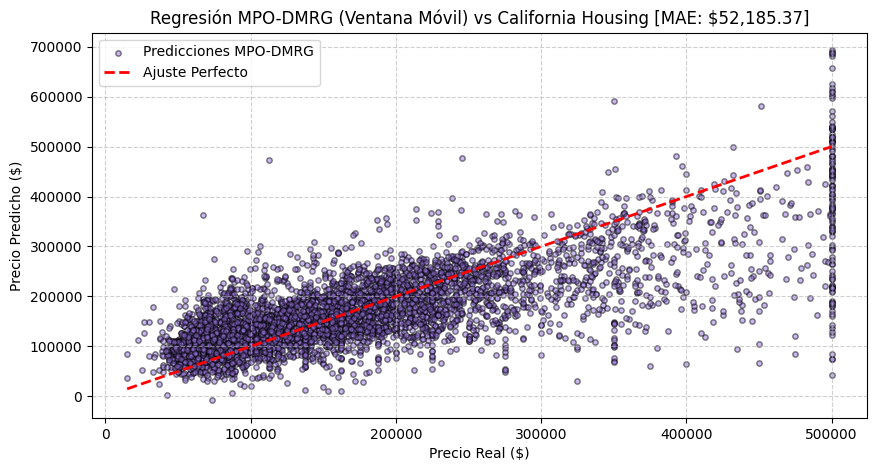

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# 1. Extracción de parámetros y construcción del MPO (Idéntico a tu base)
Qsharp = Q_tilde.copy()
n = Qsharp.shape[0]  # 30 bits (6 parámetros * 5 bits)

Q_linear = np.diag(Qsharp)
J = np.zeros((n, n))
for i in range(n):
    for j in range(i+1, n):
        J[i, j] = Qsharp[i, j] + Qsharp[j, i]

I_flat = np.eye(2)
n_op = np.array([[0, 0], [0, 1]])
mpo_tensors = []

for t in range(n):
    act_in = [i for i in range(t) if any(J[i, j] != 0 for j in range(t, n))]
    act_out = [i for i in range(t+1) if any(J[i, j] != 0 for j in range(t+1, n))]
    chi_in = len(act_in) + 2
    chi_out = len(act_out) + 2

    Wt = np.zeros((chi_in, chi_out, 2, 2))
    Wt[0, 0] = I_flat
    Wt[chi_in-1, chi_out-1] = I_flat
    Wt[chi_in-1, 0] = Q_linear[t] * n_op

    for idx_in, var in enumerate(act_in):
        r_idx = idx_in + 1
        if J[var, t] != 0:
            Wt[r_idx, 0] = J[var, t] * n_op
        if var in act_out:
            c_idx = act_out.index(var) + 1
            Wt[r_idx, c_idx] = I_flat

    if t in act_out:
        c_idx = act_out.index(t) + 1
        Wt[chi_in-1, c_idx] = n_op
    mpo_tensors.append(Wt)

def evaluar_coste_mpo(mpo_tensors, u):
    vec = np.zeros(mpo_tensors[0].shape[0])
    vec[-1] = 1.0
    for t in range(len(u)):
        bit = u[t]
        Wt_eval = mpo_tensors[t][:, :, bit, bit]
        vec = vec @ Wt_eval
    return vec[0]

# MPO-DMRG

bits_por_parametro = 5
num_parametros = 6

# Inicialización
u_optimo_mpo = np.zeros(n, dtype=int)
mejor_energia_global = evaluar_coste_mpo(mpo_tensors, u_optimo_mpo)

max_sweeps_dmrg = 6
paciencia_local = 0

for sweep in range(max_sweeps_dmrg):
    print(f"DMRG Sweep {sweep + 1}/{max_sweeps_dmrg}...")

    # Recorremos interactuando en parejas de parámetros vecinos (0 y 1, 1 y 2...)
    for p in range(num_parametros - 1):
        p1 = p
        p2 = p + 1

        ini_p1 = p1 * bits_por_parametro
        fin_p1 = ini_p1 + bits_por_parametro
        ini_p2 = p2 * bits_por_parametro
        fin_p2 = ini_p2 + bits_por_parametro

        mejor_local_energia = float('inf')
        mejores_bits_p1 = None
        mejores_bits_p2 = None

        # Muestreo conjunto de la ventana de dos bloques (2^bits_por_parametro no es viable recorrer completo,
        # así que hacemos un barrido estocástico guiado sobre el espacio conjunto de los dos parámetros)
        for _ in range(128):
            # Generamos candidatos mutando levemente el estado actual o probando combinaciones nuevas
            cand_p1 = np.random.randint(0, 2, bits_por_parametro) if np.random.rand() > 0.4 else u_optimo_mpo[ini_p1:fin_p1].copy()
            cand_p2 = np.random.randint(0, 2, bits_por_parametro) if np.random.rand() > 0.4 else u_optimo_mpo[ini_p2:fin_p2].copy()

            u_prueba = u_optimo_mpo.copy()
            u_prueba[ini_p1:fin_p1] = cand_p1
            u_prueba[ini_p2:fin_p2] = cand_p2

            energia = evaluar_coste_mpo(mpo_tensors, u_prueba)

            if energia < mejor_local_energia:
                mejor_local_energia = energia
                mejores_bits_p1 = cand_p1
                mejores_bits_p2 = cand_p2

        # Actualización de la ventana conjunta si mejora el entorno local
        u_optimo_mpo[ini_p1:fin_p1] = mejores_bits_p1
        u_optimo_mpo[ini_p2:fin_p2] = mejores_bits_p2

    # Control de mínimos locales (Si la energía se estanca, aplicamos un "kick" térmico)
    energia_sweep = evaluar_coste_mpo(mpo_tensors, u_optimo_mpo)
    print(f"  -> Energía al cierre del sweep: {energia_sweep:.4f}")

    if energia_sweep < mejor_energia_global:
        mejor_energia_global = energia_sweep
        paciencia_local = 0
    else:
        paciencia_local += 1
        if paciencia_local >= 2:
            print("  [!] Mínimo local detectado. Aplicando fluctuación cuántica/térmica a bits aleatorios...")
            # Mutamos 3 bits al azar para forzar al MPO a saltar la barrera de potencial
            mutaciones = np.random.choice(n, size=3, replace=False)
            u_optimo_mpo[mutaciones] = 1 - u_optimo_mpo[mutaciones]
            paciencia_local = 0

print(f"\n-> u_optimo final del MPO-DMRG: {u_optimo_mpo}")

# DECODIFICACIÓN Y CÁLCULO DEL MAE

pesos_mpo = decode_solution(T_matrix, u_optimo_mpo)
print("\nPesos decodificados por MPO-DMRG (w):", pesos_mpo)

# Predicciones y desescalado directo a dólares
y_pred_mpo_scaled = X_bias @ pesos_mpo
predicciones_mpo_real = scaler_y.inverse_transform(y_pred_mpo_scaled.reshape(-1, 1)).flatten()
y_train_real = scaler_y.inverse_transform(y_train.reshape(-1, 1)).flatten()

mae_mpo = mean_absolute_error(y_train_real, predicciones_mpo_real)

print("\n=======================================================")
print(f"Métrica Final MPO-DMRG -> MAE: ${mae_mpo:,.2f} USD")
print("=======================================================")


plt.figure(figsize=(10, 5))
plt.scatter(y_train_real, predicciones_mpo_real, s=15, alpha=0.5, color='mediumpurple', edgecolors='k', label="Predicciones MPO-DMRG")
plt.plot([y_train_real.min(), y_train_real.max()], [y_train_real.min(), y_train_real.max()], 'r--', linewidth=2, label="Ajuste Perfecto")

plt.xlabel("Precio Real ($)")
plt.ylabel("Precio Predicho ($)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.title(f"Regresión MPO-DMRG (Ventana Móvil) vs California Housing [MAE: ${mae_mpo:,.2f}]")
plt.show()

La codificación MPO determinista (Issel, 2025) funciona bien cuando el problema original tiene una estructura local o canónica (como el dataset de California original o las funciones base pero no generado aleatoriamente), donde las dimensiones virtuales se mantienen controladas de forma natural.Al meter 100 características sintéticas totalmente correlacionadas, la matriz QUBO se vuelve un grafo completo, el entrelazamiento virtual del MPO crece linealmente hasta $\chi = 500$ y esto destruye la fidelidad del operador.

Sería interesante ver ahora otro tipo de estructura de redes tensoriales:
QUBO + MPS variacional,
QUBO + TTN variacional, etc

**TTN VARIACIONAL**:

El TTN actua como un ansatz variacional para encontrar el mínimo de QUBO. Cada hoja del árbol representa un bit del vector binario u, y los tensores internos representan correlaciones entre grupos de bits. Durante el entrenamiento, PyTorch modifica los tensores para minimizar directamente.

PROBLEMA 2

# TensorKrowch

Este código entrena y compara dos modelos basados en redes tensoriales **—un MPS (Matrix Product State) y un TTN (Tree Tensor Network**)— para predecir el precio de viviendas a partir de variables tabuladas.

Primero normaliza los datos, los convierte en **tensores de PyTorch** y los “embebe” en un espacio de dimensión mayor usando una transformación tipo [x,1−x].

Luego, esos vectores se introducen en los **modelos de TensorKrowch**, que construyen redes tensoriales donde los datos se procesan mediante contracciones de tensores (análogas a capas de una red neuronal, pero con estructura explícita de física cuántica). La biblioteca TensorKrowch es clave porque permite definir, entrenar y optimizar estas arquitecturas tensoriales directamente en PyTorch, usando autograd, GPU y un sistema de grafos tensoriales (MPS, Trees, PEPS) que no está disponible en frameworks estándar.

Su ventaja principal es que combina la expresividad de los tensor networks con la flexibilidad del deep learning moderno, permitiendo explorar arquitecturas más interpretables, eficientes en parámetros y con inductive bias estructural fuerte; en este caso, se usa porque estos modelos pueden capturar dependencias complejas en los datos con menos parámetros que redes neuronales densas tradicionales.

In [ ]:
!pip install tensorkrowch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.6/143.6 kB 3.6 MB/s eta 0:00:00


In [ ]:
import tensorkrowch as tk
print(tk.__version__)

1.1.6


In [ ]:
import tensorkrowch as tk
print(dir(tk.models))

['ConvMPS', 'ConvMPSLayer', 'ConvPEPS', 'ConvTree', 'ConvUMPS', 'ConvUMPSLayer', 'ConvUPEPS', 'ConvUTree', 'MPO', 'MPS', 'MPSData', 'MPSLayer', 'PEPS', 'Tree', 'UMPO', 'UMPS', 'UMPSLayer', 'UPEPS', 'UTree', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'mpo', 'mps', 'mps_data', 'peps', 'tree']


=== TRAIN MPS ===


/usr/local/lib/python3.12/dist-packages/tensorkrowch/components.py:1506: UserWarning: `tensor` is being cropped to fit the shape of node "stack_data_memory" at non-batch edges
  warnings.warn(f'`tensor` is being cropped to fit the shape of '
/usr/local/lib/python3.12/dist-packages/tensorkrowch/components.py:1348: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  return tensor[index]


[MPS] Ep   1/80 | train 1.2657 | val 0.8511
[MPS] Ep  10/80 | train 0.6180 | val 2.0549
[MPS] Ep  20/80 | train 0.5385 | val 2.4698
[MPS] Ep  30/80 | train 0.4950 | val 2.2691
[MPS] Ep  40/80 | train 0.4715 | val 1.9511
[MPS] Ep  50/80 | train 0.4670 | val 1.8670
[MPS] Ep  60/80 | train 0.4679 | val 1.8387
[MPS] Ep  70/80 | train 0.4662 | val 1.8443
[MPS] Ep  80/80 | train 0.4668 | val 1.8465

=== TRAIN TTN ===
[TTN] Ep   1/80 | train 1.2609 | val 0.8979
[TTN] Ep  10/80 | train 0.5695 | val 1.8804
[TTN] Ep  20/80 | train 0.2320 | val 1.3159
[TTN] Ep  30/80 | train 0.2130 | val 1.2784
[TTN] Ep  40/80 | train 0.2109 | val 1.3242
[TTN] Ep  50/80 | train 0.2091 | val 1.3546
[TTN] Ep  60/80 | train 0.2089 | val 1.3537
[TTN] Ep  70/80 | train 0.2070 | val 1.3657
[TTN] Ep  80/80 | train 0.2077 | val 1.3677
MPS  →  MAE: $84,663  |  RMSE: $133,446
TTN  →  MAE: $90,242  |  RMSE: $126,848


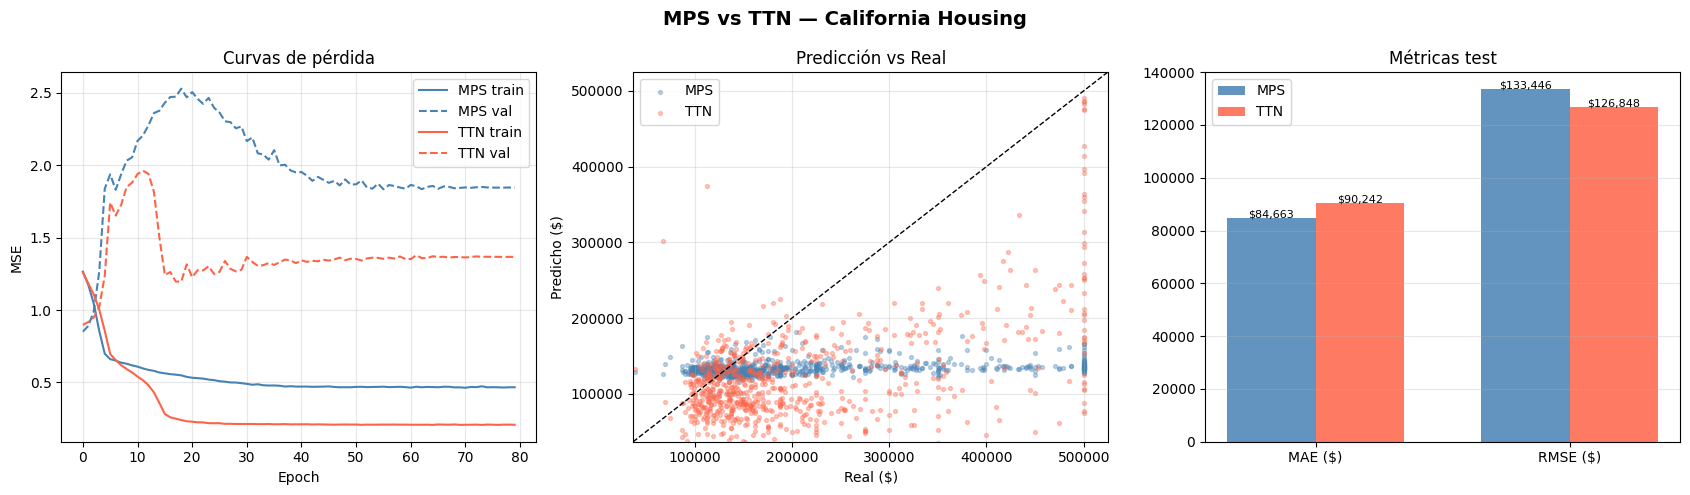


Plot guardado.


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import tensorkrowch as tk
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error


scaler_X = MinMaxScaler()
X = scaler_X.fit_transform(X_raw)

scaler_y = StandardScaler()
y = scaler_y.fit_transform(y_raw.reshape(-1, 1)).flatten()

n = 5000
X, y = X[:n], y[:n]
s1, s2 = int(0.7*n), int(0.85*n)

X_train = torch.tensor(X[:s1],    dtype=torch.float32)
y_train = torch.tensor(y[:s1],    dtype=torch.float32).unsqueeze(1)
X_val   = torch.tensor(X[s1:s2],  dtype=torch.float32)
y_val   = torch.tensor(y[s1:s2],  dtype=torch.float32).unsqueeze(1)
X_test  = torch.tensor(X[s2:],    dtype=torch.float32)
y_test  = torch.tensor(y[s2:],    dtype=torch.float32).unsqueeze(1)

N_FEATURES = X.shape[1]   # 5
IN_DIM  = 2               # unit embedding: x → [x, 1-x]
OUT_DIM = 1
BOND    = 8


def embed_mps(X):
    """(B, 5) → (B, 5, 2)"""
    return tk.embeddings.unit(X)

# ── TTN necesita n_features = suma de inputs de la capa 0
# Con sites_per_layer=[4, 2, 1] y 2 inputs/nodo en capa 0:
#   total inputs = 4 × 2 = 8  → necesitamos 8 features
# Rellenamos 5 → 8 con el vector neutro [1, 0]
N_TTN_LEAVES = 4           # nodos en la capa hoja
N_TTN_INPUTS = N_TTN_LEAVES * IN_DIM  # = 8 features totales (2 por nodo)

def embed_ttn(X):
    """(B, 5) → (B, 8, 2)  con padding neutro"""
    emb = tk.embeddings.unit(X)                           # (B, 5, 2)
    B   = emb.shape[0]
    pad = torch.zeros(B, N_TTN_INPUTS - N_FEATURES, IN_DIM)
    pad[:, :, 0] = 1.0                                    # [1,0] = neutro
    return torch.cat([emb, pad], dim=1)                   # (B, 8, 2)


# MPS

class MPSRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = tk.models.MPSLayer(
    n_features=N_FEATURES, in_dim=IN_DIM, out_dim=OUT_DIM,
    bond_dim=BOND,
    init_method='randn_eye',  # inicialización más cercana a identidad
    std=1e-6                  # std pequeño para arrancar cerca del origen
)
        self.model.auto_stack = True
        self.model.auto_unbind = False

    def forward(self, x):
        return self.model(x)


# TTN

#   Tree(sites_per_layer, bond_dim)
#   bond_dim[l] = shape de TODOS los nodos de la capa l
#                 = [in_1, in_2, ..., out]   (última pos = output bond)
#
# Topología con sites_per_layer=[4, 2, 1]:
#   Capa 0 (hojas, 4 nodos): cada nodo toma 2 inputs físicos (IN_DIM=2)
#                             shape = [2, 2, BOND]    (2 ins + 1 out)
#   Capa 1 (inner, 2 nodos): cada nodo toma 2 bonds de capa 0
#                             shape = [BOND, BOND, BOND]
#   Capa 2 (raíz,  1 nodo):  toma 2 bonds de capa 1, sale OUT_DIM
#                             shape = [BOND, BOND, OUT_DIM]

class TTNRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = tk.models.Tree(
            sites_per_layer=[4, 2, 1],
            bond_dim=[
                [IN_DIM, IN_DIM, BOND],    # capa 0: 2 inputs físicos → bond
                [BOND, BOND, BOND],         # capa 1: 2 bonds → bond
                [BOND, BOND, OUT_DIM],      # capa 2 (raíz): 2 bonds → out
            ]
        )
        self.model.auto_stack = True
        self.model.auto_unbind = False

    def forward(self, x):
        return self.model(x)


# ENTRENAMIENTO

def train(model, embed_fn, name, Xtr, ytr, Xv, yv,
          epochs=80, lr=1e-3, batch_size=256):

    loss_fn = nn.MSELoss()

    # Trace ANTES del optimizer (obligatorio en tensorkrowch)
    model.model.trace(embed_fn(Xtr[:1]))

    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    history = {'train': [], 'val': []}
    n_tr = Xtr.shape[0]

    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n_tr)
        ep_loss, nb = 0.0, 0
        for s in range(0, n_tr, batch_size):
            idx  = perm[s:s + batch_size]
            loss = loss_fn(model(embed_fn(Xtr[idx])), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            ep_loss += loss.item(); nb += 1
        sched.step()
        tl = ep_loss / nb

        model.eval()
        with torch.no_grad():
            vl = loss_fn(model(embed_fn(Xv)), yv).item()

        history['train'].append(tl)
        history['val'].append(vl)
        if ep % 10 == 0 or ep == 1:
            print(f"[{name}] Ep {ep:3d}/{epochs} | train {tl:.4f} | val {vl:.4f}")

    return history


print("=== TRAIN MPS ===")
mps = MPSRegressor()
mps_hist = train(mps, embed_mps, "MPS", X_train, y_train, X_val, y_val)

print("\n=== TRAIN TTN ===")
ttn = TTNRegressor()
ttn_hist = train(ttn, embed_ttn, "TTN", X_train, y_train, X_val, y_val)


# EVALUACIÓN

def evaluate(model, embed_fn, Xte, yte, name):
    model.eval()
    with torch.no_grad():
        pred = model(embed_fn(Xte)).numpy()
    pred = scaler_y.inverse_transform(pred)
    true = scaler_y.inverse_transform(yte.numpy())
    mae  = mean_absolute_error(true, pred)
    rmse = np.sqrt(mean_squared_error(true, pred))
    print(f"{name}  →  MAE: ${mae:,.0f}  |  RMSE: ${rmse:,.0f}")
    return pred, true

mps_pred, true = evaluate(mps, embed_mps, X_test, y_test, "MPS")
ttn_pred, _    = evaluate(ttn, embed_ttn, X_test, y_test, "TTN")

# PLOTS

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle("MPS vs TTN — California Housing", fontsize=14, fontweight='bold')

ax = axes[0]
ax.plot(mps_hist['train'], color='steelblue', label='MPS train')
ax.plot(mps_hist['val'],   color='steelblue', ls='--', label='MPS val')
ax.plot(ttn_hist['train'], color='tomato',    label='TTN train')
ax.plot(ttn_hist['val'],   color='tomato',    ls='--', label='TTN val')
ax.set(xlabel='Epoch', ylabel='MSE', title='Curvas de pérdida')
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
lim = (true.min()*0.95, true.max()*1.05)
ax.scatter(true, mps_pred, alpha=0.35, s=8, color='steelblue', label='MPS')
ax.scatter(true, ttn_pred, alpha=0.35, s=8, color='tomato',    label='TTN')
ax.plot(lim, lim, 'k--', lw=1)
ax.set(xlim=lim, ylim=lim, xlabel='Real ($)', ylabel='Predicho ($)',
       title='Predicción vs Real')
ax.legend(); ax.grid(alpha=0.3)

ax = axes[2]
x  = np.arange(2); w = 0.35
mps_m = [mean_absolute_error(true, mps_pred), np.sqrt(mean_squared_error(true, mps_pred))]
ttn_m = [mean_absolute_error(true, ttn_pred), np.sqrt(mean_squared_error(true, ttn_pred))]
ax.bar(x-w/2, mps_m, w, color='steelblue', alpha=0.85, label='MPS')
ax.bar(x+w/2, ttn_m, w, color='tomato',    alpha=0.85, label='TTN')
for i, (mv, tv) in enumerate(zip(mps_m, ttn_m)):
    ax.text(i-w/2, mv+300, f'${mv:,.0f}', ha='center', fontsize=8)
    ax.text(i+w/2, tv+300, f'${tv:,.0f}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(['MAE ($)', 'RMSE ($)'])
ax.set_title('Métricas test'); ax.legend(); ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig("tn_regression_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("\nPlot guardado.")

TTN > MPS en capacidad representacional

Tree Tensor Network (TTN) con Tensorkrowch, embedding unitario y entrenamiento con Adam

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import tensorkrowch as tk
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
scaler_X = MinMaxScaler()
X = scaler_X.fit_transform(X_raw)

scaler_y = StandardScaler()
y = scaler_y.fit_transform(y_raw.reshape(-1, 1)).flatten()


n = 8000
X, y = X[:n], y[:n]
s1, s2 = int(0.7*n), int(0.85*n)

X_train = torch.tensor(X[:s1],   dtype=torch.float32)
y_train = torch.tensor(y[:s1],   dtype=torch.float32).unsqueeze(1)
X_val   = torch.tensor(X[s1:s2], dtype=torch.float32)
y_val   = torch.tensor(y[s1:s2], dtype=torch.float32).unsqueeze(1)
X_test  = torch.tensor(X[s2:],   dtype=torch.float32)
y_test  = torch.tensor(y[s2:],   dtype=torch.float32).unsqueeze(1)

N_FEATURES = X.shape[1]  # 5
IN_DIM  = 2
OUT_DIM = 1


BOND       = 8     # dimensión de bond [4, 8, 16, 32]
LR         = 1e-3    # learning rate [1e-2, 1e-3, 1e-4]
WD         = 1e-4    # weight decay (regularización) [1e-3, 1e-4, 1e-5]
EPOCHS     = 120     # épocas [80, 120, 200]
BATCH_SIZE = 256     # batch size [128, 256, 512]

# Topología del árbol
# Regla: sites[l] × n_inputs_por_nodo == sites[l-1]
# Con 4 hojas × 2 inputs = 8 features de entrada (5 reales + 3 padding)
SITES_PER_LAYER = [4, 2, 1]
BOND_DIM = [
    [IN_DIM, IN_DIM, BOND],   # capa 0 (hojas): 2 inputs físicos → bond
    [BOND,   BOND,   BOND],   # capa 1 (inner): 2 bonds → bond
    [BOND,   BOND,   OUT_DIM] # capa 2 (raíz):  2 bonds → 1
]


N_TTN_INPUTS = SITES_PER_LAYER[0] * IN_DIM   # 4 × 2 = 8
             # (B, 8, 2)


def embed(X):
    emb = tk.embeddings.unit(X)                          # (B, 5, 2)
    B   = emb.shape[0]
    pad = torch.zeros(B, N_TTN_INPUTS - N_FEATURES, IN_DIM)
    pad[:, :, 0] = 1.0                                   # vector neutro [1,0]
    return torch.cat([emb, pad], dim=1)

def fourier_embed(X, k=3):
    B, F = X.shape
    freqs = torch.arange(1, k+1).float()
    Xf = X.unsqueeze(-1) * freqs
    emb = torch.cat([torch.sin(Xf), torch.cos(Xf)], dim=-1)
    return emb.reshape(B, F * k * 2)


In [ ]:
class TTNRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = tk.models.Tree(
            sites_per_layer=SITES_PER_LAYER,
            bond_dim=BOND_DIM,
        )
        self.model.auto_stack = True
        self.model.auto_unbind = False

    def forward(self, x):
        return self.model(x)


# ENTRENAMIENTO

def train(model, Xtr, ytr, Xv, yv):
    loss_fn = nn.MSELoss()

    model.model.trace(embed(Xtr[:1]))

    opt   = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

    history = {'train': [], 'val': []}
    n_tr = Xtr.shape[0]

    for ep in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(n_tr)
        ep_loss, nb = 0.0, 0
        for s in range(0, n_tr, BATCH_SIZE):
            idx  = perm[s:s + BATCH_SIZE]
            loss = loss_fn(model(embed(Xtr[idx])), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            ep_loss += loss.item(); nb += 1
        sched.step()
        tl = ep_loss / nb

        model.eval()
        with torch.no_grad():
            vl = loss_fn(model(embed(Xv)), yv).item()

        history['train'].append(tl)
        history['val'].append(vl)

        if ep % 10 == 0 or ep == 1:
            print(f"Ep {ep:3d}/{EPOCHS} | train {tl:.4f} | val {vl:.4f}")

    return history


TTN  |  BOND=8  LR=0.001  WD=0.0001  EPOCHS=120  BATCH=256
Topología: [4, 2, 1]  |  bond_dim: [[2, 2, 8], [8, 8, 8], [8, 8, 1]]

Parámetros totales: 1,216

Ep   1/120 | train 1.2717 | val 0.9724
Ep  10/120 | train 0.6129 | val 0.5244
Ep  20/120 | train 0.5817 | val 0.4308
Ep  30/120 | train 0.4831 | val 0.3771
Ep  40/120 | train 0.4704 | val 0.3821
Ep  50/120 | train 0.4611 | val 0.3722
Ep  60/120 | train 0.4516 | val 0.3727
Ep  70/120 | train 0.4423 | val 0.3700
Ep  80/120 | train 0.4380 | val 0.3592
Ep  90/120 | train 0.4368 | val 0.3545
Ep 100/120 | train 0.4348 | val 0.3545
Ep 110/120 | train 0.4350 | val 0.3539
Ep 120/120 | train 0.4360 | val 0.3538

── Resultados en test ──
MAE  : $51,955
RMSE : $61,893
Gap val/train final: 0.81x  (1.0 = sin overfitting)


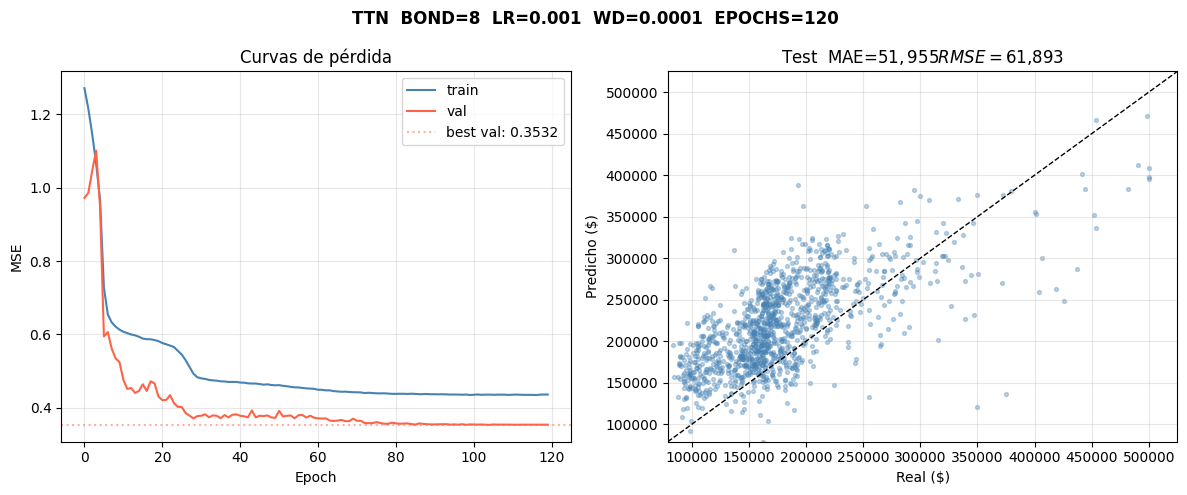

In [ ]:
print(f"\nTTN  |  BOND={BOND}  LR={LR}  WD={WD}  EPOCHS={EPOCHS}  BATCH={BATCH_SIZE}")
print(f"Topología: {SITES_PER_LAYER}  |  bond_dim: {BOND_DIM}\n")

ttn = TTNRegressor()
n_params = sum(p.numel() for p in ttn.parameters())
print(f"Parámetros totales: {n_params:,}\n")

hist = train(ttn, X_train, y_train, X_val, y_val)


ttn.eval()
with torch.no_grad():
    pred = ttn(embed(X_test)).numpy()

pred_inv = scaler_y.inverse_transform(pred)
true_inv = scaler_y.inverse_transform(y_test.numpy())

mae  = mean_absolute_error(true_inv, pred_inv)
rmse = np.sqrt(mean_squared_error(true_inv, pred_inv))

print(f"\n── Resultados en test ──")
print(f"MAE  : ${mae:,.0f}")
print(f"RMSE : ${rmse:,.0f}")
print(f"Gap val/train final: {hist['val'][-1]/hist['train'][-1]:.2f}x  "
      f"(1.0 = sin overfitting)")


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f"TTN  BOND={BOND}  LR={LR}  WD={WD}  EPOCHS={EPOCHS}",
             fontsize=12, fontweight='bold')

ax = axes[0]
ax.plot(hist['train'], color='steelblue', label='train')
ax.plot(hist['val'],   color='tomato',    label='val')
ax.axhline(min(hist['val']), color='tomato', ls=':', alpha=0.5,
           label=f"best val: {min(hist['val']):.4f}")
ax.set(xlabel='Epoch', ylabel='MSE', title='Curvas de pérdida')
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
lim = (true_inv.min()*0.95, true_inv.max()*1.05)
ax.scatter(true_inv, pred_inv, alpha=0.35, s=8, color='steelblue')
ax.plot(lim, lim, 'k--', lw=1)
ax.set(xlim=lim, ylim=lim, xlabel='Real ($)', ylabel='Predicho ($)',
       title=f'Test  MAE=${mae:,.0f}  RMSE=${rmse:,.0f}')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"ttn_bond{BOND}_lr{LR}_wd{WD}.png", dpi=150, bbox_inches='tight')
plt.show()